# Diagnosticar y actualizar: gradientes y optimizadores

El notebook anterior trató el primer paso del entrenamiento: medir el error con una función de pérdida. Este trata los otros dos:

- **Diagnosticar**: `perdida.backward()` calcula un gradiente para cada parámetro, que dice cómo cambia la pérdida si ese parámetro se mueve.
- **Actualizar**: `optimizador.step()` usa esos gradientes para mover los parámetros.

Entre los dos está `optimizador.zero_grad()`, y el orden de las tres llamadas importa más de lo que parece: hay órdenes equivocados que no dan ningún error y dejan al modelo sin aprender. La matemática de cada optimizador está en `04-matematica-de-pytorch/04_optimizadores`, en el módulo 1. Aquí los usamos sobre MNIST.

**Contenido**

1. Preparación
2. Un gradiente por parámetro
3. `backward()` calcula, `step()` mueve
4. Qué dice un gradiente
5. Por qué `zero_grad()`
6. El orden importa
7. Acumular gradientes a propósito
8. La tasa de aprendizaje
9. Por qué `Adam` no usa la tasa de `SGD`
10. Resumen y ejercicios

## 1. Preparación

Precargamos MNIST en memoria, como en `00-datos` (sección 9), para que cada entrenamiento tarde segundos. La red es la de todo el módulo: 784 → 128 → 10.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)


def precargar(entrenamiento):
    datos = datasets.MNIST(root="../data", train=entrenamiento, download=True)
    imagenes = ((datos.data.float() / 255 - 0.1307) / 0.3081).unsqueeze(1)
    return imagenes, datos.targets


X_entrenamiento, y_entrenamiento = precargar(True)
X_prueba, y_prueba = precargar(False)
datos_entrenamiento = TensorDataset(X_entrenamiento, y_entrenamiento)


def nueva_red():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


def nuevo_cargador():
    """Lotes de 64 mezclados, siempre en el mismo orden para que las comparaciones sean justas."""
    return DataLoader(datos_entrenamiento, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(1))


def exactitud(modelo):
    with torch.no_grad():
        return (modelo(X_prueba).argmax(dim=1) == y_prueba).float().mean().item()


criterio = nn.CrossEntropyLoss()
x, y = next(iter(nuevo_cargador()))
print("un lote:", tuple(x.shape), tuple(y.shape))

un lote: (64, 1, 28, 28) (64,)


## 2. Un gradiente por parámetro

La red tiene 101.770 parámetros (`01-modelos/01_nn_module`, sección 7). Antes del primer `backward()` ninguno tiene gradiente. Después, cada uno tiene el suyo, guardado en `.grad` con la misma forma que el parámetro:

In [2]:
torch.manual_seed(0)
red = nueva_red()
print("parámetros:", sum(p.numel() for p in red.parameters()))
print("gradiente antes de backward:", red[1].weight.grad)

perdida = criterio(red(x), y)
perdida.backward()

print(f"\npérdida del lote: {perdida.item():.4f}\n")
for nombre, p in red.named_parameters():
    print(f"{nombre:9s} parámetro {str(tuple(p.shape)):10s} gradiente {str(tuple(p.grad.shape)):10s}"
          f" |gradiente| medio {p.grad.abs().mean().item():.5f}")

parámetros: 101770
gradiente antes de backward: None

pérdida del lote: 2.2663

1.weight  parámetro (128, 784) gradiente (128, 784) |gradiente| medio 0.00417
1.bias    parámetro (128,)     gradiente (128,)     |gradiente| medio 0.00420
3.weight  parámetro (10, 128)  gradiente (10, 128)  |gradiente| medio 0.01560
3.bias    parámetro (10,)      gradiente (10,)      |gradiente| medio 0.03324


Una sola llamada a `backward()` calculó 101.770 números: cuánto cambia la pérdida de este lote si se mueve cada parámetro un poquito. Es la retropropagación de `04-matematica-de-pytorch/01_autograd_y_regla_de_la_cadena`, hecha por autograd.

## 3. `backward()` calcula, `step()` mueve

Un error común es pensar que `backward()` actualiza los pesos. No los toca: solo llena `.grad`. Lo comprobamos guardando una copia de los pesos antes de cada llamada:

In [3]:
torch.manual_seed(0)
red = nueva_red()
optimizador = torch.optim.SGD(red.parameters(), lr=0.1)
pesos = red[3].weight

antes = pesos.detach().clone()
perdida = criterio(red(x), y)
perdida.backward()
print("¿backward() cambió los pesos?", not torch.equal(antes, pesos))

gradiente = pesos.grad.clone()
optimizador.step()
print("¿step() cambió los pesos?    ", not torch.equal(antes, pesos))
print("¿step() hizo w - lr * gradiente?", torch.allclose(pesos, antes - 0.1 * gradiente))

¿backward() cambió los pesos? False
¿step() cambió los pesos?     True
¿step() hizo w - lr * gradiente? True


`step()` de `SGD` hace exactamente $w \leftarrow w - \text{lr} \cdot \nabla w$ en cada parámetro. Otros optimizadores hacen cuentas más elaboradas con el gradiente, pero siempre es `step()` el que mueve.

## 4. Qué dice un gradiente

El gradiente de un parámetro funciona como un puntaje de diagnóstico:

- **El signo** dice hacia dónde moverlo. Si es positivo, subir ese peso sube la pérdida, así que conviene bajarlo. Si es negativo, conviene subirlo.
- **La magnitud** dice cuánto influye. Un peso con gradiente grande mueve mucho la pérdida; uno con gradiente casi cero casi no la afecta, al menos en este lote.

Lo comprobamos con el peso de la capa de salida que tiene el gradiente más grande. Lo movemos un poco hacia arriba y hacia abajo, y comparamos el cambio de la pérdida con lo que predice el gradiente: $\Delta \text{pérdida} \approx \text{gradiente} \cdot \Delta w$.

In [4]:
torch.manual_seed(0)
red = nueva_red()
perdida = criterio(red(x), y)
perdida.backward()

W = red[3].weight
fila, columna = divmod(W.grad.abs().argmax().item(), W.shape[1])
g = W.grad[fila, columna].item()
print(f"peso [{fila}, {columna}] de la capa de salida: valor {W[fila, columna].item():.4f}, gradiente {g:.4f}\n")

for delta in [0.01, -0.01]:
    with torch.no_grad():
        W[fila, columna] += delta
        nueva = criterio(red(x), y).item()
        W[fila, columna] -= delta
    print(f"moverlo {delta:+.2f}: la pérdida cambia {nueva - perdida.item():+.6f}   (el gradiente predice {g * delta:+.6f})")

peso [0, 4] de la capa de salida: valor -0.0148, gradiente -0.1708

moverlo +0.01: la pérdida cambia -0.001705   (el gradiente predice -0.001708)
moverlo -0.01: la pérdida cambia +0.001709   (el gradiente predice +0.001708)


El gradiente es negativo: subir ese peso baja la pérdida, y bajarlo la sube, en la cantidad que predijo. Es el **descenso de gradiente**: el gradiente es la pendiente de la colina en ese punto, y el optimizador da un paso cuesta abajo, en la dirección contraria al gradiente.

## 5. Por qué `zero_grad()`

`backward()` no reemplaza lo que hay en `.grad`: **le suma** el gradiente nuevo. Si se llama dos veces sobre el mismo lote, el gradiente queda al doble:

In [5]:
torch.manual_seed(0)
red = nueva_red()
optimizador = torch.optim.SGD(red.parameters(), lr=0.1)

criterio(red(x), y).backward()
una_vez = red[3].weight.grad.clone()
criterio(red(x), y).backward()
print("¿Dos backward() dan el doble?", torch.allclose(red[3].weight.grad, 2 * una_vez))

optimizador.zero_grad()
print("después de zero_grad():", red[3].weight.grad)

¿Dos backward() dan el doble? True
después de zero_grad(): None


`zero_grad()` borra los gradientes. Desde PyTorch 2.0 no los deja en cero sino en `None` (`set_to_none=True`), que ahorra memoria y le avisa al optimizador que no hay gradiente.

PyTorch suma en vez de reemplazar porque así se pueden juntar gradientes de varios cálculos, algo que se usa a propósito (sección 7). Pero en un entrenamiento normal cada paso tiene que usar solo el gradiente de su lote, y por eso se limpian en cada vuelta.

## 6. El orden importa

El orden correcto de cada paso es: limpiar, predecir, medir, calcular gradientes, mover.

```python
optimizador.zero_grad()
perdida = criterio(modelo(x), y)
perdida.backward()
optimizador.step()
```

Probamos qué pasa con cuatro desórdenes típicos. Cada uno es una función que hace un paso de entrenamiento:

In [6]:
def paso_correcto(modelo, optimizador, x, y):
    optimizador.zero_grad()
    perdida = criterio(modelo(x), y)
    perdida.backward()
    optimizador.step()
    return perdida


def paso_zero_grad_tarde(modelo, optimizador, x, y):
    perdida = criterio(modelo(x), y)
    perdida.backward()
    optimizador.zero_grad()       # borra lo que backward() acaba de calcular
    optimizador.step()
    return perdida


def paso_step_antes(modelo, optimizador, x, y):
    optimizador.zero_grad()
    perdida = criterio(modelo(x), y)
    optimizador.step()            # todavía no hay gradientes
    perdida.backward()
    return perdida


def paso_sin_zero_grad(modelo, optimizador, x, y):
    perdida = criterio(modelo(x), y)
    perdida.backward()            # se suma a todo lo acumulado
    optimizador.step()
    return perdida


def paso_atrasado(modelo, optimizador, x, y):
    perdida = criterio(modelo(x), y)
    optimizador.step()            # usa los gradientes del lote anterior
    optimizador.zero_grad()
    perdida.backward()
    return perdida


def probar(paso, pasos=300):
    torch.manual_seed(0)
    modelo = nueva_red()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
    perdidas = []
    for i, (x, y) in enumerate(nuevo_cargador()):
        if i == pasos:
            break
        perdidas.append(paso(modelo, optimizador, x, y).item())
    return perdidas, exactitud(modelo)


variantes = {
    "correcto": paso_correcto,
    "zero_grad entre backward y step": paso_zero_grad_tarde,
    "step antes de backward": paso_step_antes,
    "sin zero_grad": paso_sin_zero_grad,
}
historiales = {}
for nombre, paso in variantes.items():
    historiales[nombre], acierto = probar(paso)
    print(f"{nombre:32s} pérdida media de los últimos 50 pasos {sum(historiales[nombre][-50:]) / 50:6.2f}"
          f"   exactitud de prueba {acierto:.1%}")

correcto                         pérdida media de los últimos 50 pasos   0.27   exactitud de prueba 93.2%


zero_grad entre backward y step  pérdida media de los últimos 50 pasos   2.32   exactitud de prueba 11.3%


step antes de backward           pérdida media de los últimos 50 pasos   2.32   exactitud de prueba 11.3%


sin zero_grad                    pérdida media de los últimos 50 pasos  15.69   exactitud de prueba 14.0%


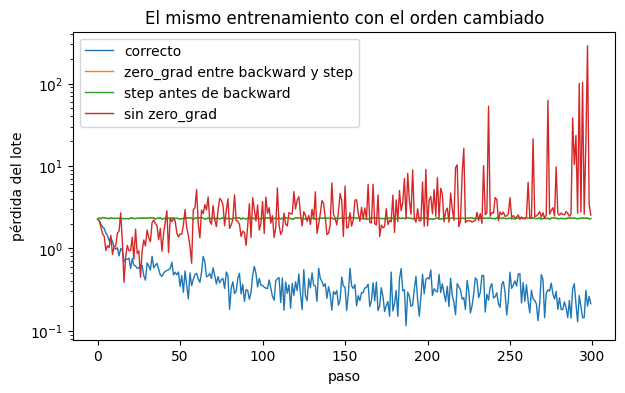

In [7]:
plt.figure(figsize=(7, 4))
for nombre, perdidas in historiales.items():
    plt.plot(perdidas, label=nombre, linewidth=1)
plt.yscale("log")
plt.xlabel("paso")
plt.ylabel("pérdida del lote")
plt.title("El mismo entrenamiento con el orden cambiado")
plt.legend()
plt.show()

Ninguna variante dio error, y solo una aprendió:

- **`zero_grad()` entre `backward()` y `step()`**: el gradiente se borra justo antes de usarlo. `step()` encuentra `None` en todos los parámetros y no mueve nada. La pérdida se queda en 2.3, cerca de $\log 10 \approx 2.30$: la de un modelo que reparte la probabilidad por igual entre los 10 dígitos. La exactitud, 11%, es la de adivinar.
- **`step()` antes de `backward()`**, con `zero_grad()` al principio: cuando llega `step()`, los gradientes del paso anterior ya se borraron y los nuevos todavía no existen. Mismo resultado: nada se mueve. Su curva es idéntica a la anterior y la tapa en el gráfico.
- **Sin `zero_grad()`**: cada paso usa la suma de todos los gradientes anteriores. Durante los primeros pasos la pérdida baja, porque la suma todavía apunta más o menos hacia abajo. Pero los pasos se hacen cada vez más largos, y desde el paso 50 la pérdida sube y da saltos cada vez mayores, hasta cien veces la inicial.

Hay una quinta variante: mover `zero_grad()` para que `step()` encuentre los gradientes del lote anterior. Esa sí da error:

In [8]:
try:
    probar(paso_atrasado)
except RuntimeError as error:
    print("RuntimeError:", str(error)[:230], "...")

RuntimeError: one of the variables needed for gradient computation has been modified by an inplace operation: [torch.FloatTensor [128, 10]], which is output 0 of AsStridedBackward0, is at version 2; expected version 1 instead. Hint: enable anom ...


`step()` modificó los pesos en el lugar, y después `backward()` necesitaba los valores que tenían cuando se calculó la predicción. Autograd lleva la cuenta de las versiones de cada tensor y detecta el cambio. El mensaje es largo y no menciona el orden de las llamadas, pero "modified by an inplace operation" justo en `backward()` suele significar eso.

Las tres variantes silenciosas son peores que el error: el código corre, la pérdida se imprime, y solo graficarla revela que algo anda mal. Por eso conviene mirar siempre la curva de pérdida de las primeras decenas de pasos.

## 7. Acumular gradientes a propósito

La suma de `backward()` tiene un uso legítimo. Si un lote de 64 no cabe en la memoria de la GPU (`03-dispositivos`), se puede procesar en 4 trozos de 16 y llamar a `step()` una sola vez, después de los 4 `backward()`. Para que el resultado sea el mismo, cada pérdida se divide por 4: así la suma de los cuatro gradientes es el promedio sobre los 64 ejemplos, igual que con el lote entero.

In [9]:
torch.manual_seed(0)
red = nueva_red()

criterio(red(x), y).backward()                 # el lote de 64 de una vez
gradiente_entero = [p.grad.clone() for p in red.parameters()]
red.zero_grad()

for trozo_x, trozo_y in zip(x.split(16), y.split(16)):
    (criterio(red(trozo_x), trozo_y) / 4).backward()     # cuatro trozos de 16, acumulando

iguales = all(torch.allclose(g, p.grad, atol=1e-7) for g, p in zip(gradiente_entero, red.parameters()))
print("¿Mismo gradiente que el lote entero?", iguales)

¿Mismo gradiente que el lote entero? True


Dentro del ciclo de entrenamiento queda así, con `pasos_por_actualizacion = 4`:

```python
for i, (x, y) in enumerate(cargador):
    perdida = criterio(modelo(x), y) / pasos_por_actualizacion
    perdida.backward()                         # acumula
    if (i + 1) % pasos_por_actualizacion == 0:
        optimizador.step()
        optimizador.zero_grad()
```

Es el mismo `zero_grad()` de siempre, solo que se llama cada 4 lotes en vez de en cada uno.

## 8. La tasa de aprendizaje

`SGD` mueve cada peso en contra de su gradiente, multiplicado por la tasa de aprendizaje `lr`. La tasa decide el largo de los pasos al bajar la colina:

- **Muy chica**: avanza, pero tan lento que no llega a ningún lado en un tiempo razonable.
- **Adecuada**: progreso estable.
- **Muy grande**: los pasos se pasan del fondo del valle y el modelo salta de un lado al otro.

Entrenamos dos épocas con `SGD` y cuatro tasas, y con `Adam` y la tasa que recomienda el curso, `lr=0.001`:

In [10]:
def entrenar(crear_optimizador, epocas=2):
    torch.manual_seed(0)
    modelo = nueva_red()
    optimizador = crear_optimizador(modelo.parameters())
    perdidas = []
    for epoca in range(epocas):
        for x, y in nuevo_cargador():
            optimizador.zero_grad()
            perdida = criterio(modelo(x), y)
            perdida.backward()
            optimizador.step()
            perdidas.append(perdida.item())
    return perdidas, exactitud(modelo)


configuraciones = {
    "SGD, lr = 1": lambda p: torch.optim.SGD(p, lr=1.0),
    "SGD, lr = 0.1": lambda p: torch.optim.SGD(p, lr=0.1),
    "SGD, lr = 0.01": lambda p: torch.optim.SGD(p, lr=0.01),
    "SGD, lr = 0.001": lambda p: torch.optim.SGD(p, lr=0.001),
    "Adam, lr = 0.001": lambda p: torch.optim.Adam(p, lr=0.001),
}
corridas = {}
for nombre, crear in configuraciones.items():
    corridas[nombre] = entrenar(crear)
    perdidas, acierto = corridas[nombre]
    print(f"{nombre:17s} pérdida media de los últimos 100 lotes {sum(perdidas[-100:]) / 100:.3f}   exactitud de prueba {acierto:.1%}")

SGD, lr = 1       pérdida media de los últimos 100 lotes 1.687   exactitud de prueba 39.1%


SGD, lr = 0.1     pérdida media de los últimos 100 lotes 0.096   exactitud de prueba 96.3%


SGD, lr = 0.01    pérdida media de los últimos 100 lotes 0.274   exactitud de prueba 92.6%


SGD, lr = 0.001   pérdida media de los últimos 100 lotes 0.660   exactitud de prueba 86.1%


Adam, lr = 0.001  pérdida media de los últimos 100 lotes 0.091   exactitud de prueba 96.7%


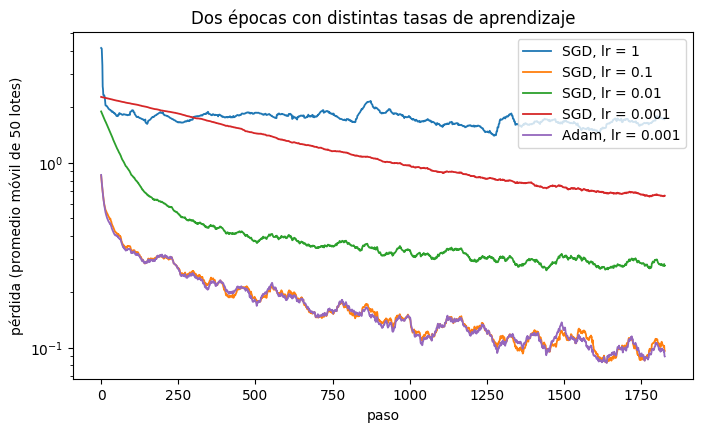

In [11]:
def suavizar(valores, ventana=50):
    valores = torch.tensor(valores)
    return valores.unfold(0, ventana, 1).mean(dim=1)


plt.figure(figsize=(8, 4.5))
for nombre, (perdidas, _) in corridas.items():
    plt.plot(suavizar(perdidas), label=nombre, linewidth=1.3)
plt.yscale("log")
plt.xlabel("paso")
plt.ylabel("pérdida (promedio móvil de 50 lotes)")
plt.title("Dos épocas con distintas tasas de aprendizaje")
plt.legend()
plt.show()

Las tres zonas aparecen:

- Con `lr = 0.001`, `SGD` baja tan despacio que después de dos épocas (1.876 pasos) sigue en 86%.
- Con `lr = 0.01` llega a 93%, y con `lr = 0.1` a 96.3%, la mejor tasa de `SGD` de las cuatro.
- Con `lr = 1` la pérdida salta y no termina de bajar: la exactitud queda en 39%.

`Adam` con `lr = 0.001` llega a lo mismo que el mejor `SGD`, y sus curvas casi se superponen. En este problema no es mejor que un `SGD` bien ajustado; lo que hace es funcionar bien sin tener que buscar la tasa. `Adam` ajusta el paso de cada peso por separado, según el tamaño típico de su gradiente, y por eso su tasa por defecto sirve en muchos problemas. Es la razón por la que suele ser la primera opción.

## 9. Por qué `Adam` no usa la tasa de `SGD`

En `SGD`, el paso de cada peso es `lr × gradiente`: si el gradiente es chico, el paso es chico. En `Adam` el paso se divide por el tamaño típico del gradiente, así que su largo queda cerca de `lr` sin importar cuánto valga el gradiente. En el primer paso, cada peso se mueve casi exactamente `lr`, sea su gradiente grande o chico (`04-matematica-de-pytorch/04_optimizadores`, sección 10).

Lo comparamos con `lr = 0.1` en los dos optimizadores, midiendo cuánto se movió cada peso en un paso:

In [12]:
for nombre, clase in [("SGD", torch.optim.SGD), ("Adam", torch.optim.Adam)]:
    torch.manual_seed(0)
    red = nueva_red()
    antes = [p.detach().clone() for p in red.parameters()]
    optimizador = clase(red.parameters(), lr=0.1)

    optimizador.zero_grad()
    criterio(red(x), y).backward()
    optimizador.step()

    movimiento = torch.cat([(p.detach() - a).abs().flatten() for p, a in zip(red.parameters(), antes)])
    print(f"{nombre:4s}: mediana del movimiento {movimiento.median().item():.5f}   máximo {movimiento.max().item():.4f}   "
          f"pesos que se movieron 0.1 (± 0.001): {((movimiento - 0.1).abs() < 0.001).float().mean():.1%}")

torch.manual_seed(0)
print(f"\ntamaño máximo de un peso inicial de la capa oculta: {nueva_red()[1].weight.abs().max().item():.4f}")

SGD : mediana del movimiento 0.00024   máximo 0.0171   pesos que se movieron 0.1 (± 0.001): 0.0%
Adam: mediana del movimiento 0.10000   máximo 0.1000   pesos que se movieron 0.1 (± 0.001): 99.7%

tamaño máximo de un peso inicial de la capa oculta: 0.0357


Con `SGD` y `lr = 0.1`, el movimiento típico de un peso (la mediana) fue de 0.0002, y el más grande, de 0.017. Con `Adam` y la misma tasa, casi todos se movieron 0.1 de golpe. (Los pocos que se movieron algo menos tienen un gradiente diminuto, comparable con el `eps` = $10^{-8}$ que `Adam` suma en el denominador para no dividir por cero.) Y los pesos iniciales de la capa oculta no pasan de 0.036: un solo paso de `Adam` con `lr = 0.1` mueve cada peso casi tres veces su tamaño inicial. Eso no es ajustar un modelo, es reemplazarlo por otro al azar en cada paso. Entrenando dos épocas:

In [13]:
for nombre, lr in [("Adam, lr = 0.1", 0.1), ("Adam, lr = 0.01", 0.01)]:
    corridas[nombre] = entrenar(lambda p: torch.optim.Adam(p, lr=lr))
for nombre in ["Adam, lr = 0.1", "Adam, lr = 0.01", "Adam, lr = 0.001"]:
    perdidas, acierto = corridas[nombre]
    print(f"{nombre:16s} pérdida máxima {max(perdidas):7.2f}   pérdida final {sum(perdidas[-100:]) / 100:.3f}   exactitud {acierto:.1%}")

Adam, lr = 0.1   pérdida máxima   73.80   pérdida final 2.271   exactitud 10.7%
Adam, lr = 0.01  pérdida máxima    2.58   pérdida final 0.188   exactitud 94.2%
Adam, lr = 0.001 pérdida máxima    2.27   pérdida final 0.091   exactitud 96.7%


Con `lr = 0.1`, `Adam` dispara la pérdida a decenas en algún momento y termina adivinando, con la exactitud del azar. Con `lr = 0.01` funciona, pero peor que con `0.001`. La tasa que funcionaba bien en `SGD` es cien veces demasiado grande para `Adam`.

Las tasas típicas de partida son `0.01` a `0.1` para `SGD` y `0.001` para `Adam`. Hay otros optimizadores, como `RMSprop`, `Adagrad` o `AdamW` (este último es `Adam` con un decaimiento de pesos mejor hecho), y su matemática está en el módulo 1. Para la mayoría de los problemas, `SGD` y `Adam` alcanzan.

## 10. Resumen

- `perdida.backward()` calcula un **gradiente por parámetro** y lo guarda en `.grad`. **No cambia los pesos.**
- `optimizador.step()` **mueve los pesos** usando los gradientes. En `SGD`: $w \leftarrow w - \text{lr} \cdot \nabla w$.
- El **signo** del gradiente dice hacia dónde sube la pérdida y la **magnitud**, cuánto influye ese peso. El optimizador se mueve en la dirección contraria.
- `backward()` **suma** al gradiente que ya había. Por eso se llama a `zero_grad()` en cada paso, que desde PyTorch 2.0 deja los gradientes en `None`.
- El orden es `zero_grad()`, predicción y pérdida, `backward()`, `step()`. Los desórdenes típicos **no dan error**: el modelo no aprende, o se desestabiliza. Solo la curva de pérdida lo delata.
- Acumular gradientes a propósito, dividiendo la pérdida por el número de trozos, equivale a un lote más grande que no cabe en memoria.
- La **tasa de aprendizaje** muy chica no avanza y muy grande salta. En MNIST, `SGD` con `lr = 0.1` y `Adam` con `lr = 0.001` llegan a lo mismo.
- `Adam` da pasos de largo cercano a `lr` sin importar el gradiente, así que **no se le puede poner la tasa de `SGD`**: con `lr = 0.1` destruye el modelo.

## Ejercicios

1. En la sección 6, cambia `SGD` por `Adam` con `lr = 0.001` en la variante "sin zero_grad". ¿Diverge como con `SGD`? ¿Por qué el comportamiento es distinto? (Piensa en qué hace `Adam` con el tamaño del gradiente.)
2. Entrena la variante "zero_grad entre backward y step" durante 2.000 pasos. ¿Aprende algo alguna vez?
3. Implementa el ciclo con acumulación de la sección 7, con lotes de 16 y 4 pasos por actualización, y compara su curva de pérdida con la de lotes de 64 sin acumular. ¿Son iguales? (Pista: ¿el orden de los ejemplos es el mismo?)
4. Busca la tasa más grande con la que `SGD` todavía funciona: prueba 0.3, 0.5 y 2.
5. Agrega `momentum=0.9` a `SGD` con `lr = 0.01`. ¿Cómo se compara con `lr = 0.1` sin momento?
6. Prueba `torch.optim.RMSprop` con `lr = 0.001` y con `lr = 0.1`. ¿Se comporta como `SGD` o como `Adam` frente a la tasa? ¿Por qué?